# Medical Insurance Cost Prediction: MLP vs SVR

Packages: NumPy, pandas, PyTorch, skorch, scikit-learn. Run `preprocessing.ipynb` first to create the train/test files.


In [2]:
# Import necessary libraries
import numpy as np
import pandas as pd
import random
import time
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from skorch import NeuralNetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.model_selection import KFold, GridSearchCV, validation_curve
from sklearn.metrics import root_mean_squared_error, mean_squared_error, r2_score

In [4]:
# Set random seeds for reproducibility
def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

seed_everything(42)

# Load preprocessed dataset
X_train = pd.read_csv("X_train.csv").values
y_train = pd.read_csv("y_train.csv").values

X_test = pd.read_csv("X_test.csv").values
y_test = pd.read_csv("y_test.csv").values

print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)

# Convert data to float32 for PyTorch compatibility
X_train = X_train.astype(np.float32)
y_train = y_train.reshape(-1, 1).astype(np.float32)

(1070, 8) (268, 8)
(1070, 1) (268, 1)


In [3]:
# Print the proportion of samples in each set
Train_prop = X_train.shape[0]/(X_train.shape[0] + X_test.shape[0])
Test_prop = X_test.shape[0]/(X_train.shape[0] + X_test.shape[0])

print(f"Train set proportion: {Train_prop:.2f}")
print(f"Test set proportion: {Test_prop:.2f}")

Train set proportion: 0.80
Test set proportion: 0.20


1) MLP Model 

In [ ]:
# MLP regressor: PyTorch module wrapped in skorch, tuned with grid search
# RMSE loss so training optimises the same metric used for model selection
class RMSELoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.mse = nn.MSELoss()

    def forward(self, yhat, y):
        return torch.sqrt(self.mse(yhat, y))

class MLP(nn.Module):
    def __init__(self, input_dim, hidden_dim, activation, num_layers, dropout):
        super().__init__()
        self.activation = activation()
        self.dropout = nn.Dropout(dropout)
        self.layers = nn.ModuleList()

        # Input layer
        self.layers.append(nn.Linear(input_dim, hidden_dim))

        # Hidden layers
        for _ in range(num_layers - 1):
            self.layers.append(nn.Linear(hidden_dim, hidden_dim))

        self.output_layer = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        for layer in self.layers:
            x = self.activation(layer(x))
            x = self.dropout(x)
        x = self.output_layer(x)
        return x

# Wrap the model in skorch
model = NeuralNetRegressor(
    module=MLP,
    module__input_dim=8,
    module__hidden_dim=64,
    module__activation=nn.ReLU,
    module__num_layers=3,
    module__dropout=0.2,
    criterion=RMSELoss,
    optimizer=optim.Adam,
    verbose=0
)

# Set the parameter grid for Grid Search
param_grid = [
    {
        # ADAM settings
        'mlp__optimizer': [optim.Adam],
        'mlp__optimizer__lr': [0.001, 0.0001],
        'mlp__module__hidden_dim': [16, 32],
        'mlp__module__num_layers': [2, 3],
        'mlp__module__activation': [nn.ReLU, nn.Tanh],
        'mlp__optimizer__weight_decay': [0, 0.001, 0.0001],
        'mlp__max_epochs': [400],
        'mlp__batch_size': [16, 32],
        'mlp__module__dropout': [0.2, 0.3]
    },
    {
        # SGD settings
        'mlp__optimizer': [optim.SGD],
        'mlp__optimizer__momentum': [0.9, 0.99],
        'mlp__optimizer__lr': [0.001, 0.0001],
        'mlp__module__hidden_dim': [16, 32],
        'mlp__module__num_layers': [2, 3],
        'mlp__module__activation': [nn.ReLU, nn.Tanh],
        'mlp__optimizer__weight_decay': [0, 0.001, 0.0001],
        'mlp__max_epochs': [400],
        'mlp__batch_size': [16, 32],
        'mlp__module__dropout': [0.2, 0.3]
    }
]

# Define evaluation metrics
scores = {'rmse': 'neg_root_mean_squared_error', 'mse': 'neg_mean_squared_error', 'r2': 'r2'}

# Create a pipeline to scale the data and train the model
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('mlp', model)
])

# Fixed, shuffled 5-fold CV so both models are tuned on the same folds
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Measure training time for grid search
grid_search_start = time.time()

# Run the Grid Search
gs = GridSearchCV(estimator=pipe, param_grid=param_grid, scoring=scores, n_jobs=-1, refit='rmse', cv=cv, verbose=1, return_train_score=True)

gs.fit(X_train, y_train)

# Measure end time for the grid search and calculate duration 
grid_search_end = time.time()
grid_search_time = grid_search_end - grid_search_start

# Store the best model
best_mlp = gs.best_estimator_

# Print the best model hyperparameters
print(f"Best hyperparameters: {gs.best_params_}")

# Save the results
results = gs.cv_results_
best_index = gs.best_index_

# Print the best scores for log-RMSE, log-MSE, and R2
print(f"Best Configuration Training log-RMSE: {-results['mean_train_rmse'][best_index]:.4f}")
print(f"Best Configuration Training log-MSE: {-results['mean_train_mse'][best_index]:.4f}")
print(f"Best Configuration Training R2 score: {results['mean_train_r2'][best_index]:.4f}")

print(f"Best CV Mean log-RMSE score: {-results['mean_test_rmse'][best_index]:.4f}")
print(f"Best CV Mean log-MSE score: {-results['mean_test_mse'][best_index]:.4f}")
print(f"Best CV Mean R2 score: {results['mean_test_r2'][best_index]:.4f}")

Fitting 5 folds for each of 576 candidates, totalling 2880 fits
Best hyperparameters: {'mlp__batch_size': 16, 'mlp__max_epochs': 400, 'mlp__module__activation': <class 'torch.nn.modules.activation.Tanh'>, 'mlp__module__dropout': 0.2, 'mlp__module__hidden_dim': 32, 'mlp__module__num_layers': 3, 'mlp__optimizer': <class 'torch.optim.adam.Adam'>, 'mlp__optimizer__lr': 0.001, 'mlp__optimizer__weight_decay': 0}
Best Configuration Training log-RMSE: 0.3751
Best Configuration Training log-MSE: 0.1408
Best Configuration Training R2 score: 0.8303
Best CV Mean log-RMSE score: 0.3818
Best CV Mean log-MSE score: 0.1477
Best CV Mean R2 score: 0.8213


In [5]:
# Measure refit time for the best model
refit_time = gs.refit_time_

# Make sure test sets are in float32 type and reshaped
X_test = X_test.astype('float32')
y_test = y_test.astype('float32').reshape(-1, 1)

# Measure inference time on the test set
inference_start = time.time()

# Predict using the best model
y_pred = best_mlp.predict(X_test)

# Inference end time and calculate duration
inference_end = time.time()
inference_time = inference_end - inference_start

# Calculate metrics
rmse = root_mean_squared_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# Print grid search time, refit time, inference time, and final test scores
print(f"Total training time for grid search: {grid_search_time:.2f} seconds")
print(f"Refit time for the best model: {refit_time:.2f} seconds")
print(f"Inference time on the test set: {inference_time:.2f} seconds")

print(f"Final Test log-RMSE score: {rmse:.4f}")
print(f"Final Test log-MSE score: {mse:.4f}")
print(f"Final Test R2 score: {r2:.4f}")

Total training time for grid search: 8942.02 seconds
Refit time for the best model: 15.49 seconds
Inference time on the test set: 0.01 seconds
Final Test log-RMSE score: 0.3499
Final Test log-MSE score: 0.1224
Final Test R2 score: 0.8639


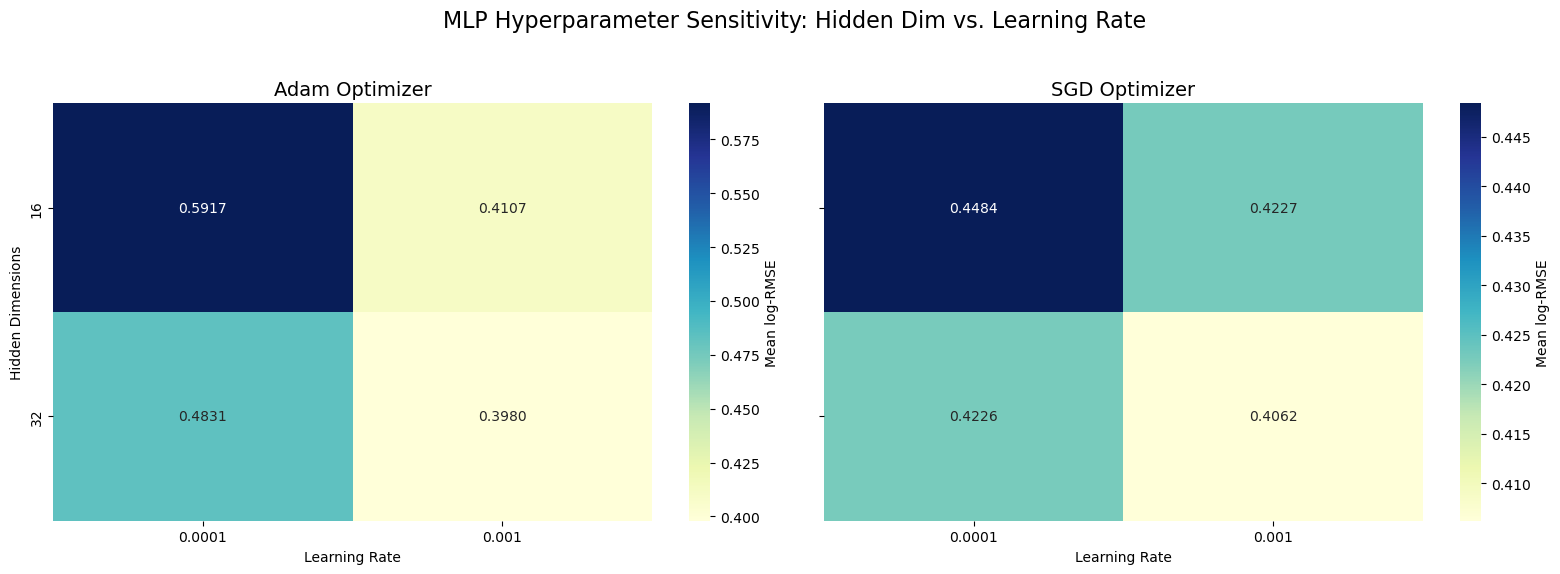

In [6]:
# Heatmap of mean CV log-RMSE by hidden dimension and learning rate, for each optimiser
results_df = pd.DataFrame(gs.cv_results_)

col_lr = 'param_mlp__optimizer__lr'
col_dim = 'param_mlp__module__hidden_dim'
col_opt = 'param_mlp__optimizer'

# Filter by the string name of the optimiser class
adam_df = results_df[results_df[col_opt].astype(str).str.contains('Adam', case=False)]
sgd_df = results_df[results_df[col_opt].astype(str).str.contains('SGD', case=False)]

# Pivot tables, negated to show positive RMSE
adam_pivot = -adam_df.pivot_table(index=col_dim, columns=col_lr, values='mean_test_rmse', aggfunc='mean')
sgd_pivot = -sgd_df.pivot_table(index=col_dim, columns=col_lr, values='mean_test_rmse', aggfunc='mean')

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

sns.heatmap(adam_pivot, annot=True, fmt=".4f", cmap='YlGnBu', ax=axes[0], cbar_kws={'label': 'Mean log-RMSE'})
axes[0].set_title("Adam Optimizer", fontsize=14)
axes[0].set_xlabel("Learning Rate")
axes[0].set_ylabel("Hidden Dimensions")

sns.heatmap(sgd_pivot, annot=True, fmt=".4f", cmap='YlGnBu', ax=axes[1], cbar_kws={'label': 'Mean log-RMSE'})
axes[1].set_title("SGD Optimizer", fontsize=14)
axes[1].set_xlabel("Learning Rate")
axes[1].set_ylabel("")

plt.suptitle("MLP Hyperparameter Sensitivity: Hidden Dim vs. Learning Rate", fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

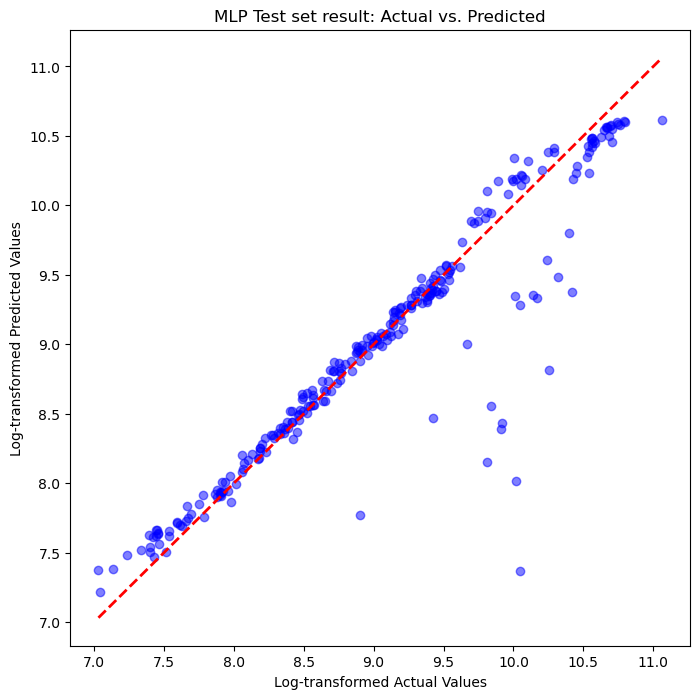

In [7]:
# Visualise actual vs predicted values on the test set
plt.figure(figsize=(8, 8))
plt.scatter(y_test, y_pred, alpha=0.5, color='blue')
plt.plot([y_test.min(), y_test.max()], 
         [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Log-transformed Actual Values')
plt.ylabel('Log-transformed Predicted Values')
plt.title('MLP Test set result: Actual vs. Predicted')
plt.show()

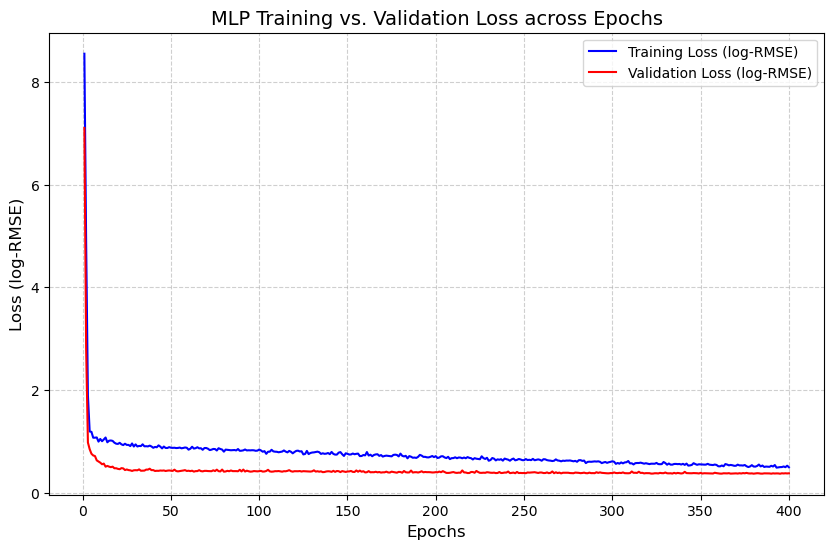

In [8]:
# Training vs validation loss across epochs (skorch's internal 80/20 split of the training data)
history = best_mlp.named_steps['mlp'].history
epochs = range(1, len(history) + 1)
train_loss = history[:, 'train_loss']
valid_loss = history[:, 'valid_loss']

# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(epochs, train_loss, 'b-', label='Training Loss (log-RMSE)')
plt.plot(epochs, valid_loss, 'r-', label='Validation Loss (log-RMSE)')

plt.title('MLP Training vs. Validation Loss across Epochs', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss (log-RMSE)', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

2. SVM (SVR) Model 

In [10]:
# Define SVR model
svr = SVR()

# Define the grid
param_grid_svr = {
    'svr__C': [0.1, 1, 10, 100, 1000],
    'svr__epsilon': [0.01, 0.1, 0.2, 0.5],
    'svr__gamma': ['scale', 'auto', 0.1, 0.01],
    'svr__kernel': ['rbf', 'poly', 'linear']
}

# Create a pipeline to scale the data and train the model
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('svr', svr)
])

# Reuse the same scoring dict and CV folds (`scores`, `cv`) as the MLP grid search

# Measure training time for grid search
grid_search_start = time.time()

# Setup the Grid Search
gs_svr = GridSearchCV(estimator=pipe, param_grid=param_grid_svr, scoring=scores, n_jobs=-1,
                      refit='rmse', cv=cv, verbose=1, return_train_score=True)

gs_svr.fit(X_train, y_train.ravel()) # ravel() converts y to the shape SVM expects

grid_search_end = time.time()
grid_search_time = grid_search_end - grid_search_start

# Save the best model and evaluate on the test set
best_svr = gs_svr.best_estimator_

# Print the best model hyperparameters
print(f"Best Params: {gs_svr.best_params_}")

# Save the results
results = gs_svr.cv_results_
best_index = gs_svr.best_index_

# Print the best scores for log-RMSE, log-MSE, and R2
print(f"Best Configuration Training log-RMSE score: {-results['mean_train_rmse'][best_index]:.4f}")
print(f"Best Configuration Training log-MSE score: {-results['mean_train_mse'][best_index]:.4f}")
print(f"Best Configuration Training R2 score: {results['mean_train_r2'][best_index]:.4f}")

print(f"Best CV Mean log-RMSE score: {-results['mean_test_rmse'][best_index]:.4f}")
print(f"Best CV Mean log-MSE score: {-results['mean_test_mse'][best_index]:.4f}")
print(f"Best CV Mean R2 score: {results['mean_test_r2'][best_index]:.4f}")

Fitting 5 folds for each of 240 candidates, totalling 1200 fits
Best Params: {'svr__C': 1000, 'svr__epsilon': 0.1, 'svr__gamma': 0.01, 'svr__kernel': 'rbf'}
Best Configuration Training log-RMSE score: 0.3669
Best Configuration Training log-MSE score: 0.1347
Best Configuration Training R2 score: 0.8376
Best CV Mean log-RMSE score: 0.3730
Best CV Mean log-MSE score: 0.1411
Best CV Mean R2 score: 0.8292


In [11]:
# Measure refit time for the best model
refit_time = gs_svr.refit_time_

# Measure inference time on the test set
inference_start = time.time()

# Predict using the best model
y_pred = best_svr.predict(X_test)

# Inference end time and calculate duration
inference_end = time.time()
inference_time = inference_end - inference_start

# Calculate metrics
rmse = root_mean_squared_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Final Test log-RMSE score: {rmse:.4f}")
print(f"Final Test log-MSE score: {mse:.4f}")
print(f"Final Test R2 score: {r2:.4f}")

print(f"Total training time for grid search: {grid_search_time:.2f} seconds")
print(f"Refit time for the best model: {refit_time:.2f} seconds")
print(f"Inference time on the test set: {inference_time:.2f} seconds")

Final Test log-RMSE score: 0.3482
Final Test log-MSE score: 0.1213
Final Test R2 score: 0.8651
Total training time for grid search: 710.54 seconds
Refit time for the best model: 0.71 seconds
Inference time on the test set: 0.01 seconds


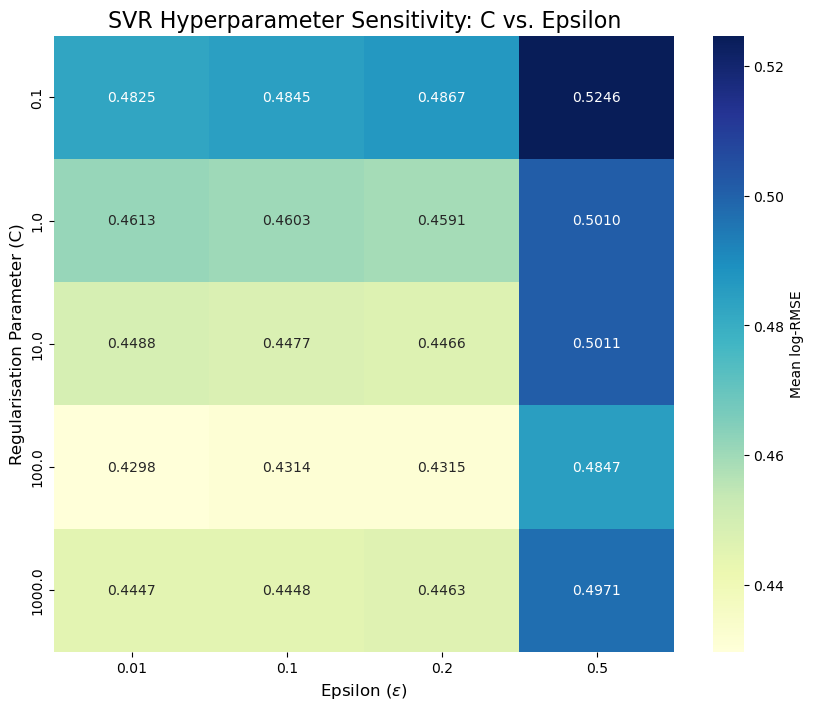

In [12]:
# Heatmap of mean CV log-RMSE by C and epsilon (averaged over gamma and kernel)
results_svr_df = pd.DataFrame(gs_svr.cv_results_)

svr_pivot = -results_svr_df.pivot_table(index='param_svr__C',
                                        columns='param_svr__epsilon',
                                        values='mean_test_rmse',
                                        aggfunc='mean')

plt.figure(figsize=(10, 8))
sns.heatmap(svr_pivot, annot=True, fmt=".4f", cmap='YlGnBu', cbar_kws={'label': 'Mean log-RMSE'})

plt.title("SVR Hyperparameter Sensitivity: C vs. Epsilon", fontsize=16)
plt.xlabel(r"Epsilon ($\epsilon$)", fontsize=12)
plt.ylabel("Regularisation Parameter (C)", fontsize=12)
plt.show()

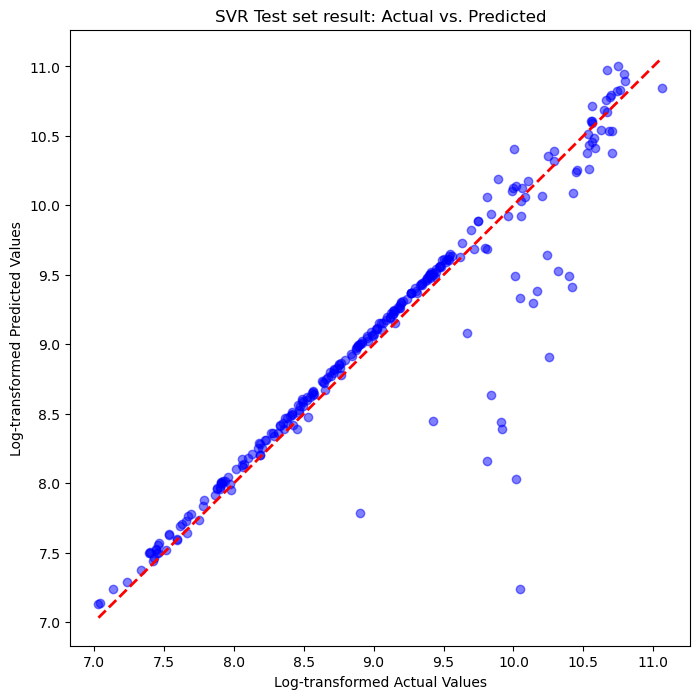

In [13]:
# Visualise actual vs predicted values on the test set
plt.figure(figsize=(8, 8))
plt.scatter(y_test, y_pred, alpha=0.5, color='blue')
plt.plot([y_test.min(), y_test.max()], 
         [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Log-transformed Actual Values')
plt.ylabel('Log-transformed Predicted Values')
plt.title('SVR Test set result: Actual vs. Predicted')
plt.show()

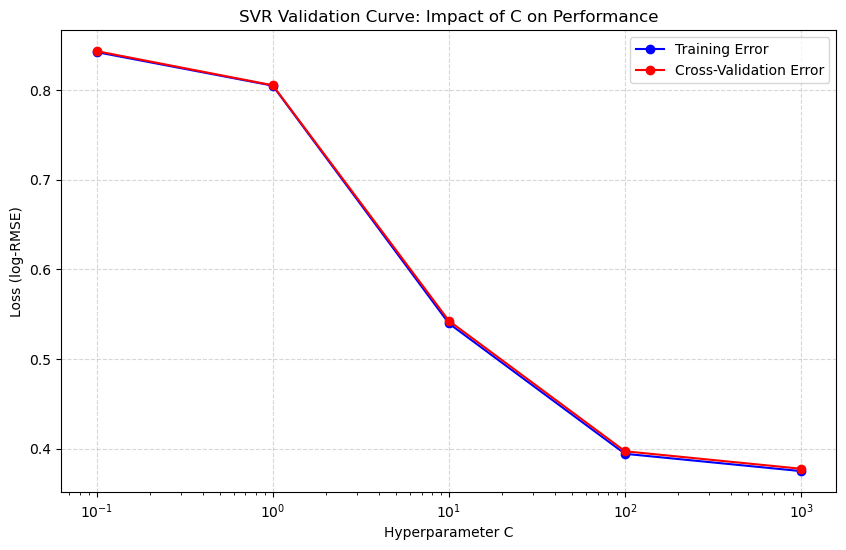

In [14]:
# Validation curve for C (RBF SVR, default gamma and epsilon)
param_range = [0.1, 1, 10, 100, 1000]
train_scores, test_scores = validation_curve(
    SVR(kernel='rbf'), X_train, y_train.ravel(), 
    param_name="C", param_range=param_range,
    cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1
)

# Mean error across folds
train_mean = -np.mean(train_scores, axis=1)
test_mean = -np.mean(test_scores, axis=1)

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(param_range, train_mean, label="Training Error", color="blue", marker='o')
plt.plot(param_range, test_mean, label="Cross-Validation Error", color="red", marker='o')

plt.xscale('log')
plt.xlabel('Hyperparameter C')
plt.ylabel('Loss (log-RMSE)')
plt.title('SVR Validation Curve: Impact of C on Performance')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Save the validation curve data so evaluate_saved_models.ipynb can plot it without refitting
cv_data = pd.DataFrame({
    'param_range': param_range,
    'train_mean': train_mean,
    'test_mean': test_mean
})
cv_data.to_csv("svr_validation_curve_data.csv", index=False)

Models saved successfully!
Final Test log-RMSE score for MLP: 0.3499
Final Test log-MSE score for MLP: 0.1224
Final Test R2 score for MLP: 0.8639
Final Test log-RMSE score for SVR: 0.3482
Final Test log-MSE score for SVR: 0.1213
Final Test R2 score for SVR: 0.8651


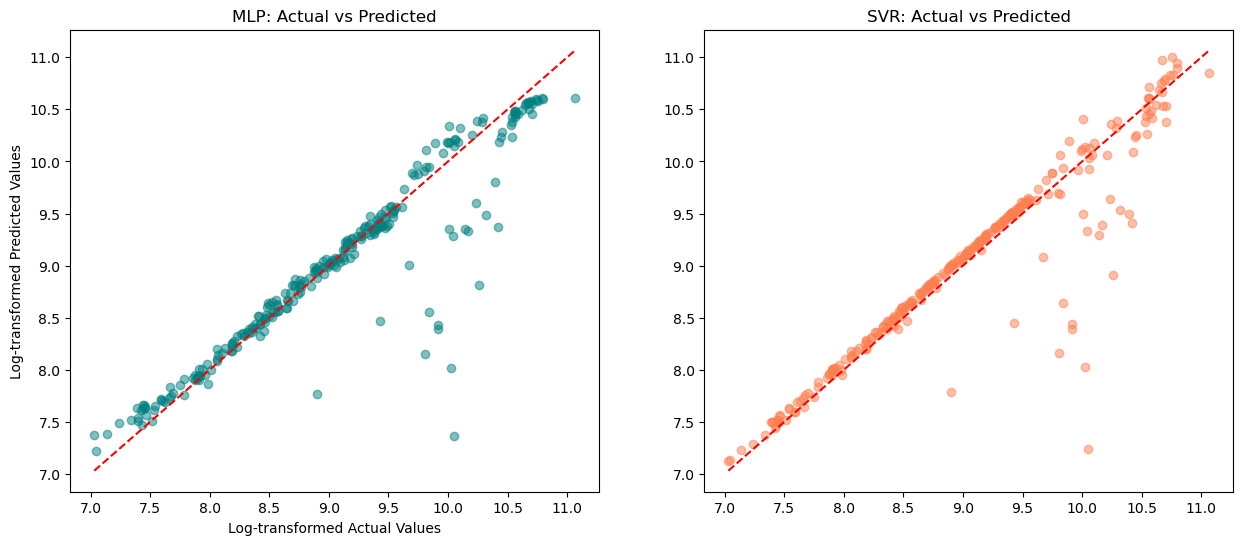

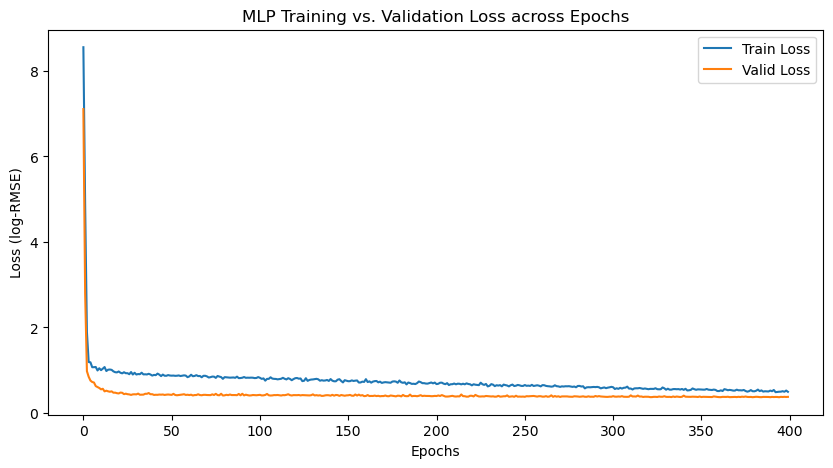

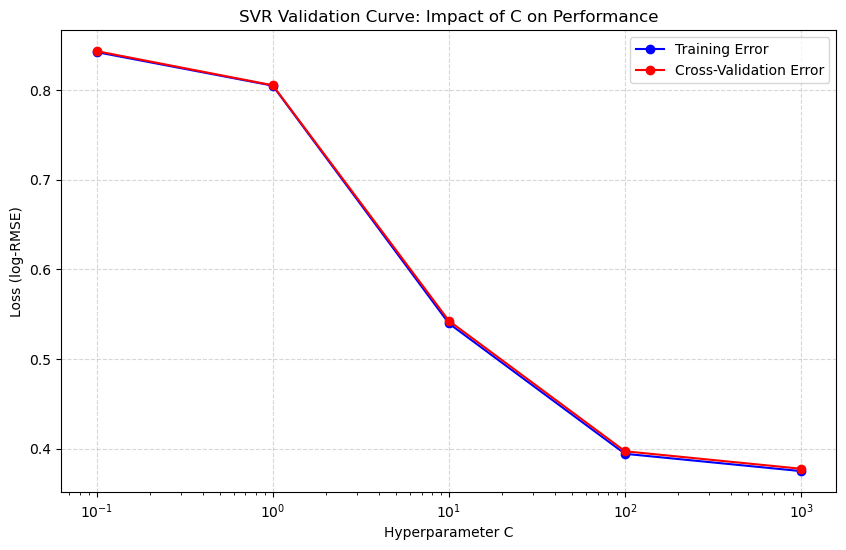

In [15]:
# Save the MLP model
with open('best_mlp_model.pkl', 'wb') as f:
    pickle.dump(best_mlp, f)

# Save the SVR model
with open('best_svr_model.pkl', 'wb') as f:
    pickle.dump(best_svr, f)

print("Models saved successfully!")

# Reload the saved models and test data to check the saved files reproduce the results

X_test = pd.read_csv("X_test.csv").values.astype('float32')
y_test = pd.read_csv("y_test.csv").values.astype('float32').reshape(-1, 1)

# Load the saved models
with open('best_mlp_model.pkl', 'rb') as f:
    loaded_mlp = pickle.load(f)

with open('best_svr_model.pkl', 'rb') as f:
    loaded_svr = pickle.load(f)

# Run Predictions
y_pred_mlp = loaded_mlp.predict(X_test)
y_pred_svr = loaded_svr.predict(X_test)

# Calculate metrics
mse_mlp = mean_squared_error(y_test, y_pred_mlp)
rmse_mlp = root_mean_squared_error(y_test, y_pred_mlp)
r2_mlp = r2_score(y_test, y_pred_mlp)
mse_svr = mean_squared_error(y_test, y_pred_svr)
rmse_svr = root_mean_squared_error(y_test, y_pred_svr)
r2_svr = r2_score(y_test, y_pred_svr)

# Print final test scores
print(f"Final Test log-RMSE score for MLP: {rmse_mlp:.4f}")
print(f"Final Test log-MSE score for MLP: {mse_mlp:.4f}")
print(f"Final Test R2 score for MLP: {r2_mlp:.4f}")
print(f"Final Test log-RMSE score for SVR: {rmse_svr:.4f}")
print(f"Final Test log-MSE score for SVR: {mse_svr:.4f}")
print(f"Final Test R2 score for SVR: {r2_svr:.4f}")

# Visualisation 1: Actual vs Predicted 
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# MLP Plot
axes[0].scatter(y_test, y_pred_mlp, alpha=0.5, color='teal')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
axes[0].set_title('MLP: Actual vs Predicted')
axes[0].set_xlabel('Log-transformed Actual Values')
axes[0].set_ylabel('Log-transformed Predicted Values')

# SVR Plot
axes[1].scatter(y_test, y_pred_svr, alpha=0.5, color='coral')
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
axes[1].set_title('SVR: Actual vs Predicted')
axes[1].set_xlabel('Log-transformed Actual Values')
axes[1].set_ylabel('Log-transformed Predicted Values')

plt.show()

# Visualisation 2: MLP Loss Curve (From History)
history = loaded_mlp.named_steps['mlp'].history
plt.figure(figsize=(10, 5))
plt.plot(history[:, 'train_loss'], label='Train Loss')
plt.plot(history[:, 'valid_loss'], label='Valid Loss')
plt.title('MLP Training vs. Validation Loss across Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss (log-RMSE)')
plt.legend()
plt.show()

# Visualisation 3: SVR Validation Curve (From Saved Data)
validation_curve_data = pd.read_csv("svr_validation_curve_data.csv")
plt.figure(figsize=(10, 6))
plt.plot(validation_curve_data['param_range'], validation_curve_data['train_mean'],
         label="Training Error", color="blue", marker='o')
plt.plot(validation_curve_data['param_range'], validation_curve_data['test_mean'],
         label="Cross-Validation Error", color="red", marker='o')

plt.xscale('log')
plt.xlabel('Hyperparameter C')
plt.ylabel('Loss (log-RMSE)')
plt.title('SVR Validation Curve: Impact of C on Performance')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [16]:
# Transform back to original scale (dollars) for comparison
y_test_original = np.exp(y_test)
y_pred_mlp_original = np.exp(y_pred_mlp)
y_pred_svr_original = np.exp(y_pred_svr)

mlp_rmse_original = root_mean_squared_error(y_test_original, y_pred_mlp_original)
mlp_mse_original = mean_squared_error(y_test_original, y_pred_mlp_original)
svr_rmse_original = root_mean_squared_error(y_test_original, y_pred_svr_original)
svr_mse_original = mean_squared_error(y_test_original, y_pred_svr_original)

print(f"True MLP RMSE in original scale: ${mlp_rmse_original:.2f}")
print(f"True MLP MSE in original scale: ${mlp_mse_original:.2f}")

print(f"True SVR RMSE in original scale: ${svr_rmse_original:.2f}")
print(f"True SVR MSE in original scale: ${svr_mse_original:.2f}")

True MLP RMSE in original scale: $4811.26
True MLP MSE in original scale: $23148220.00
True SVR RMSE in original scale: $4730.76
True SVR MSE in original scale: $22380089.87
